# Diffusion models, Lecture 1b: learning to denoise (DDPM training and sampling)

**Problem.** In [Lecture 1a](lecture1a_forward_process.ipynb) a fixed recipe turned clean digits into pure noise. Generation needs the opposite direction: start from pure noise and end with a **new** digit. Adding noise needed no knowledge at all; removing it does, because deciding which specks are noise and which are the stroke of a digit requires knowing what digits look like. So this half of the diffusion model is **learned**.

This lecture trains a network to predict the noise in a noisy image, uses it in a 1,000-step sampling loop to generate new digits, and then runs the **same sampling loop** on a published model trained on colour images (Ho et al., 2020).

**What you will learn**

1. Why the reverse direction must be **learned**, and why the network is trained to **predict the noise**.
2. What the denoising network (a **U-Net**) receives and returns, and why it needs the **timestep**.
3. How **training** (one random noise level per image) differs from **sampling** (many steps from pure noise).
4. Why sampling is slow, and what a generated image is and is not.

**Prerequisites:** [Lecture 1a](lecture1a_forward_process.ipynb) (Gaussian noise, the one-jump formula and the noise schedule; Section 1 recaps them), and the Module 1 lectures on encoder–decoder networks (convolutions, downsampling and upsampling, skip connections). Mean squared error is refreshed where it is used.

**Setup and downloads.** Run on **Kaggle with a T4 GPU and internet on**. Run the whole notebook once before class: it takes a few minutes, most of it training in Section 3.

| Section | What | Download | Licence |
| --- | --- | ---: | --- |
| 1 | MNIST handwritten digits (via `torchvision`) | about 12 MB | see the dataset page (LeCun, Cortes & Burges) |
| 5 | `google/ddpm-cifar10-32`: the DDPM of Ho et al. (2020), trained on CIFAR-10 | 143 MB | Apache-2.0 |

Sections 1–4 also run on a CPU, but training then takes much longer; set `EPOCHS = 1` to try it.

**About the saved outputs.** The outputs and the numbers quoted in the "Reading the output" notes come from one run on a Kaggle T4 GPU (PyTorch 2.11, torchvision 0.26, diffusers 0.40) on 17 October 2026, made when Lectures 1a and 1b were a single notebook. The cell in Section 1 that rebuilds the schedule was added afterwards and prints nothing. A rerun gives slightly different numbers and different samples, even with the same seeds, because GPU arithmetic is not exactly reproducible and library versions change.

In [1]:
import math
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms.functional as TF
from matplotlib.patches import FancyBboxPatch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
torch.manual_seed(SEED)
DATA_DIR = Path("data")          # MNIST is downloaded here; nothing else is written to disk
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)


def to_display(x):
    """Images in [-1, 1] (our working range) -> [0, 1] for plotting. Values outside are clipped for display only."""
    return ((x.detach().float().cpu() + 1) / 2).clamp(0, 1)


def show_row(images, titles=None, size=1.6, suptitle=None):
    """One row of images, each (C, H, W) in [-1, 1]."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(size * n, size * 1.15))
    for i, ax in enumerate(axes if n > 1 else [axes]):
        img = to_display(images[i])
        ax.imshow(img.permute(1, 2, 0).squeeze(), cmap="gray" if img.shape[0] == 1 else None, vmin=0, vmax=1)
        ax.axis("off")
        if titles:
            ax.set_title(titles[i], fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout(); plt.show()


def show_grid(images, nrow=8, title=None, size=8):
    grid = torchvision.utils.make_grid(to_display(images), nrow=nrow, padding=2, pad_value=1)
    plt.figure(figsize=(size, size * grid.shape[1] / grid.shape[2]))
    plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
    if title:
        plt.title(title)
    plt.show()

PyTorch 2.4.0+cu121 | torchvision 0.19.0+cu121 | device: cuda


## 1. Recap of Lecture 1a, and the data

Lecture 1a built the **forward process**. Everything in this lecture uses these facts from it:

| From Lecture 1a | In one line |
| --- | --- |
| Clean images $x_0$ | MNIST digits rescaled from $[0, 1]$ to $[-1, 1]$, shape `(1, 28, 28)`, so that they are centred on zero like the noise |
| Noise $\epsilon \sim \mathcal{N}(0, I)$ | One independent $\mathcal{N}(0, 1)$ number per pixel, same shape as the image: `torch.randn_like(x)` |
| Noise schedule | $\beta_t$ rises linearly from 0.0001 to 0.02 over $T = 1000$ steps; $\alpha_t = 1 - \beta_t$ and $\bar\alpha_t = \alpha_1 \alpha_2 \cdots \alpha_t$ |
| One-jump formula | $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$ makes a noisy image at **any** level $t$ in one step (`add_noise`) |
| End point | $\bar\alpha_T$ is almost 0, so $x_T$ is close to pure $\mathcal{N}(0, I)$ noise, whatever image we started from |
| Visibility | The digit is clear at $t = 100$, barely visible at $t = 250$ and gone from $t = 500$; fine detail disappears first |

Two points that are easy to confuse:

- **A timestep is not a training step.** $t$ counts noising steps applied to one image, from $0$ to $T$. It has nothing to do with the epochs and parameter updates of the training loop in Section 3, where each image in a batch gets its own randomly chosen $t$.
- **Training and sampling must use the same scale.** The network learns on images in $[-1, 1]$, so it also generates images in $[-1, 1]$; `to_display` maps them to $[0, 1]$ only for plotting. The labels are loaded only for plotting too: the model in this lecture never sees them.

The next two cells load the data and rebuild the schedule and `add_noise` exactly as in Lecture 1a.

> **Download:** the next cell downloads MNIST (about 12 MB) into `data/`.

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [01:17<00:00, 127419.50it/s]


Extracting data/MNIST/raw/train-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 92699.05it/s]


Extracting data/MNIST/raw/train-labels-idx1-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1648877/1648877 [00:12<00:00, 128412.40it/s]


Extracting data/MNIST/raw/t10k-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 1238817.06it/s]


Extracting data/MNIST/raw/t10k-labels-idx1-ubyte.gz to data/MNIST/raw

training images: (60000, 1, 28, 28) | value range: -1.0 to 1.0


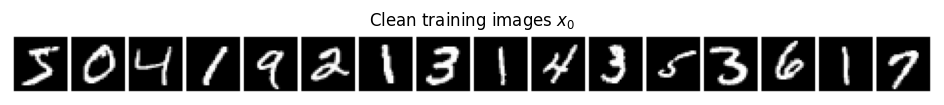

In [2]:
mnist_train = torchvision.datasets.MNIST(DATA_DIR, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(DATA_DIR, train=False, download=True)
X_train = (mnist_train.data.float() / 255 * 2 - 1).unsqueeze(1).to(DEVICE)    # (60000, 1, 28, 28), values in [-1, 1]
X_test = (mnist_test.data.float() / 255 * 2 - 1).unsqueeze(1).to(DEVICE)      # (10000, 1, 28, 28)
print("training images:", tuple(X_train.shape), "| value range:", X_train.min().item(), "to", X_train.max().item())
show_grid(X_train[:16], nrow=16, title="Clean training images $x_0$", size=12)

In [ ]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=DEVICE)          # linear schedule of Ho et al. (2020), as in Lecture 1a
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)                     # alpha_bars[t] = product of alphas[0..t]


def add_noise(x0, t, noise):
    """The forward process in one step: x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * noise.
    x0, noise: (B, C, H, W); t: (B,) integer timesteps. Returns x_t with the same shape as x0."""
    ab = alpha_bars[t].view(-1, 1, 1, 1)                      # (B,) -> (B, 1, 1, 1) for broadcasting
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

## 2. Reversing the process: learn to predict the noise

To generate, we must go from $x_T$ back to $x_0$. Why can we not just subtract the noise? Because at generation time there **is** no known noise. During training we create $x_t$ ourselves, so we know exactly which $\epsilon$ we added. At generation time we start from a fresh random tensor: there is no original image hidden in it and no record of which noise to remove. A heavily noised image is consistent with many different clean images, so the reverse step can only move towards a **plausible** image, using knowledge of what images look like.

DDPM turns that into a supervised learning problem (Ho et al., 2020). We train a network $\epsilon_\theta$ (the subscript $\theta$ marks its trainable weights) to look at a noisy image and **predict the noise in it**:

```text
input:   noisy image x_t  (1 × 28 × 28)   and   timestep t  (one integer)
output:  predicted noise ε̂ = ε_θ(x_t, t)   (1 × 28 × 28, same shape as the input)
target:  the noise ε that we actually added   (known, because we drew it)
```

Two design points:

- **Why predict the noise, and not the clean image?** Both carry the same information: given $x_t$, $t$ and a noise estimate, the forward equation can be solved for an estimate of $x_0$. Predicting $\epsilon$ is what Ho et al. found to train best, and its target always has the same simple scale (mean 0, standard deviation 1) at every noise level.
- **Why give it $t$?** The same noisy-looking patch means different things at different noise levels: at $t = 50$ almost everything is image, at $t = 900$ almost everything is noise. One network handles all 1000 levels, so it must be told which one it is looking at.

**The network: a U-Net.** The output must be an image-sized tensor, aligned pixel by pixel with the input, so the standard choice is the **U-Net** (Ronneberger et al., 2015), an encoder–decoder like those in the earlier lectures, with two additions:

- **Skip connections** copy encoder features to the decoder at the same resolution, so fine, pixel-level information is not lost in the bottleneck.
- **A timestep embedding** turns $t$ into a vector (with sines and cosines of different frequencies, like the positional encoding of Transformers in Module 2), and each block adds it to its features, so every layer knows the noise level.

The diagram shows our small version layer by layer, using the names from the code below. Each box gives the shape of the tensor it outputs. Purple-outlined boxes are `Block`s: the only layers that receive the timestep embedding, and they never change the height and width. The grey layers do the downsampling and upsampling, and each ⊕ concatenates a skip connection with the upsampled features before the decoder `Block`.

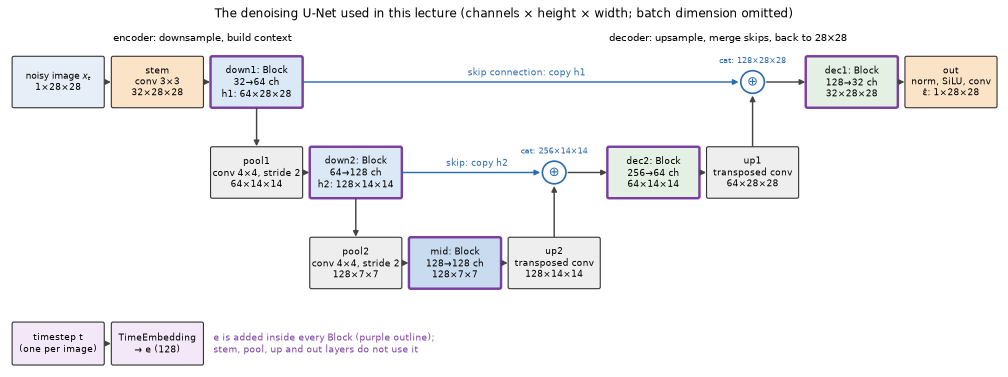

In [6]:
fig, ax = plt.subplots(figsize=(16, 5.6)); ax.set_xlim(0, 16.8); ax.set_ylim(-0.35, 5.75); ax.axis("off")
W, H = 1.5, 0.85                                  # box width and height
col = lambda i: 0.1 + 1.68 * i                     # left edge of column i
ROW = {28: 4.3, 14: 2.7, 7: 1.1}                   # bottom edge of each resolution row
BLOCK_ENC, BLOCK_DEC, BLOCK_MID = "#dbe8f5", "#e3f0e3", "#c9dcef"
RESAMPLE, CONV, IO, TIME = "#eeeeee", "#fbe3c8", "#e8eef7", "#f3e8f7"


def box(i, res, text, color, block=False):
    """Draw a layer box in column i on the row for resolution res; Blocks get a purple outline (e is added inside)."""
    x, y = col(i), ROW[res]
    edge, lw = ("#7b3fa0", 2.2) if block else ("#333", 1.0)
    ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.03", fc=color, ec=edge, lw=lw))
    ax.text(x + W / 2, y + H / 2, text, ha="center", va="center", fontsize=8)


def concat(i, res, label):
    """Draw a concatenation node above column i's centre, with its output shape."""
    cx, cy = col(i) + W / 2, ROW[res] + H / 2
    ax.add_patch(plt.Circle((cx, cy), 0.2, fc="white", ec="#2b6cb0", lw=1.5))
    ax.text(cx, cy, "⊕", ha="center", va="center", fontsize=12, color="#2b6cb0")
    ax.text(cx, cy + 0.3, label, ha="center", va="bottom", fontsize=7.5, color="#2b6cb0")
    return cx, cy


def arrow(x0, y0, x1, y1, color="#444"):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.3))


right = lambda i: col(i) + W                       # x of a box's right edge
mid_x = lambda i: col(i) + W / 2                   # x of a box's centre
mid_y = lambda res: ROW[res] + H / 2               # y of a row's centre

# Encoder (left, going down)
box(0, 28, "noisy image $x_t$\n1×28×28", IO)
box(1, 28, "stem\nconv 3×3\n32×28×28", CONV)
box(2, 28, "down1: Block\n32→64 ch\nh1: 64×28×28", BLOCK_ENC, block=True)
box(2, 14, "pool1\nconv 4×4, stride 2\n64×14×14", RESAMPLE)
box(3, 14, "down2: Block\n64→128 ch\nh2: 128×14×14", BLOCK_ENC, block=True)
box(3, 7, "pool2\nconv 4×4, stride 2\n128×7×7", RESAMPLE)
# Bottleneck
box(4, 7, "mid: Block\n128→128 ch\n128×7×7", BLOCK_MID, block=True)
# Decoder (right, going up)
box(5, 7, "up2\ntransposed conv\n128×14×14", RESAMPLE)
c2 = concat(5, 14, "cat: 256×14×14")
box(6, 14, "dec2: Block\n256→64 ch\n64×14×14", BLOCK_DEC, block=True)
box(7, 14, "up1\ntransposed conv\n64×28×28", RESAMPLE)
c1 = concat(7, 28, "cat: 128×28×28")
box(8, 28, "dec1: Block\n128→32 ch\n32×28×28", BLOCK_DEC, block=True)
box(9, 28, "out\nnorm, SiLU, conv\nε̂: 1×28×28", CONV)

# Main path
arrow(right(0), mid_y(28), col(1), mid_y(28)); arrow(right(1), mid_y(28), col(2), mid_y(28))
arrow(mid_x(2), ROW[28], mid_x(2), ROW[14] + H)                       # down1 -> pool1
arrow(right(2), mid_y(14), col(3), mid_y(14))                         # pool1 -> down2
arrow(mid_x(3), ROW[14], mid_x(3), ROW[7] + H)                        # down2 -> pool2
arrow(right(3), mid_y(7), col(4), mid_y(7)); arrow(right(4), mid_y(7), col(5), mid_y(7))
arrow(mid_x(5), ROW[7] + H, c2[0], c2[1] - 0.2)                       # up2 -> concat
arrow(c2[0] + 0.2, c2[1], col(6), mid_y(14))                          # concat -> dec2
arrow(right(6), mid_y(14), col(7), mid_y(14))                         # dec2 -> up1
arrow(mid_x(7), ROW[14] + H, c1[0], c1[1] - 0.2)                      # up1 -> concat
arrow(c1[0] + 0.2, c1[1], col(8), mid_y(28)); arrow(right(8), mid_y(28), col(9), mid_y(28))

# Skip connections: copy encoder features to the decoder at the same resolution
arrow(right(2), mid_y(28), c1[0] - 0.2, c1[1], color="#2b6cb0")
ax.text((right(2) + c1[0]) / 2, mid_y(28) + 0.08, "skip connection: copy h1", ha="center", va="bottom", fontsize=8, color="#2b6cb0")
arrow(right(3), mid_y(14), c2[0] - 0.2, c2[1], color="#2b6cb0")
ax.text((right(3) + c2[0]) / 2, mid_y(14) + 0.08, "skip: copy h2", ha="center", va="bottom", fontsize=8, color="#2b6cb0")

# Time embedding
ax.add_patch(FancyBboxPatch((col(0), -0.25), W, 0.7, boxstyle="round,pad=0.03", fc=TIME, ec="#333"))
ax.text(mid_x(0), 0.1, "timestep t\n(one per image)", ha="center", va="center", fontsize=8)
ax.add_patch(FancyBboxPatch((col(1), -0.25), W, 0.7, boxstyle="round,pad=0.03", fc=TIME, ec="#333"))
ax.text(mid_x(1), 0.1, "TimeEmbedding\n→ e (128)", ha="center", va="center", fontsize=8)
arrow(right(0), 0.1, col(1), 0.1)
ax.text(right(1) + 0.2, 0.1, "e is added inside every Block (purple outline);\nstem, pool, up and out layers do not use it",
        ha="left", va="center", fontsize=8, color="#7b3fa0")

# Headings
ax.text(col(1), 5.45, "encoder: downsample, build context", fontsize=9)
ax.text(col(6), 5.45, "decoder: upsample, merge skips, back to 28×28", fontsize=9)
plt.title("The denoising U-Net used in this lecture (channels × height × width; batch dimension omitted)", fontsize=11)
plt.show()

Every convolution in the U-Net code below follows the same pattern: **normalise → activate → convolve**.

```python
nn.Sequential(
    nn.GroupNorm(num_groups=8, num_channels=c_in),
    nn.SiLU(),
    nn.Conv2d(in_channels=c_in, out_channels=c_out, kernel_size=3, padding=1),
)
```

`nn.GroupNorm(8, c)` is **group normalisation** (Wu & He, 2018). For each image separately, it splits the channels into 8 groups and normalises each group to mean 0 and variance 1. Unlike BatchNorm, it never mixes statistics across the images in a batch, which matters here because every training batch mixes very different noise levels. The [training tricks notes](training_tricks.ipynb) explain how it works and compare it with BatchNorm and LayerNorm.

### SiLU: a smooth version of ReLU

**SiLU** (sigmoid-weighted linear unit, also called *swish*; Elfwing et al., 2018; Ramachandran et al., 2017) is the nonlinearity used throughout the U-Net and in the time-embedding MLP:

$$\text{SiLU}(x) = x \cdot \sigma(x), \qquad \sigma(x) = \frac{1}{1 + e^{-x}}.$$

The sigmoid $\sigma(x)$ lies between 0 and 1 and acts as a soft gate. For large positive $x$ it is close to 1, so the input passes almost unchanged. For large negative $x$ it is close to 0, so the input is blocked. Compare with ReLU, $\max(0, x)$, which uses a hard gate:

| $x$ | −3 | −2 | −1 | 0 | 1 | 2 | 3 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| ReLU | 0 | 0 | 0 | 0 | 1 | 2 | 3 |
| SiLU | −0.14 | −0.24 | −0.27 | 0 | 0.73 | 1.76 | 2.86 |

- **Far from zero**, SiLU behaves like ReLU: about $x$ for large positive inputs, about 0 for large negative ones.
- **Near zero**, SiLU is smooth, with no kink at 0. It lets small negative values through, dipping to a minimum of about −0.28 at $x \approx -1.28$.
- **So** the gradient does not drop abruptly to zero for every negative input, which makes units less likely to go permanently silent (the "dead ReLU" problem). The smooth curve also suits a network whose output is a fine-grained, continuous noise map. SiLU is the usual activation in DDPM-style U-Nets.

**Why normalise and activate *before* the convolution?** This order (normalisation → activation → convolution) is the "pre-activation" design of residual networks (He et al., 2016), and it matches the residual connection in each `Block`:

```python
return self.conv2(h) + self.skip(x)
```

The skip path carries `x` through untouched; only the branch that is added to it is normalised and passed through the nonlinearity. This keeps a clean path for gradients through the stacked blocks. The time embedding is added after the first convolution, so the noise-level shift is then normalised and activated together with the image features by the second GroupNorm and SiLU.

The code below is a compact version of that U-Net. You build and vary it yourself in the [DDPM lab](../../labs/diffusion/simple_ddpm_mnist.ipynb); here the points to notice are only the ones in the comments: the time embedding added in each block, the two downsampling and two upsampling stages, the two skip connections (`torch.cat`), and an output with the same shape as the input.

In [ ]:
class TimeEmbedding(nn.Module):
    """Integer timesteps (B,) -> vectors (B, dim): sines and cosines at many frequencies, then a small MLP."""
    def __init__(self, dim=128):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))

    def forward(self, t):
        # Half of the embedding holds sines, the other half cosines: 128 // 2 = 64 frequencies.
        half = self.dim // 2
        # Frequencies w_k = 10000^(-k/half) for k = 0..63: from 1 (fast, separates nearby t) down to ~0.0001 (slow, coarse level).
        # Written as exp(-log(10000) * k / half), which equals 10000^(-k/half). Shape: (half,)
        freqs = torch.exp(-math.log(10_000) * torch.arange(half, device=t.device) / half)
        # Multiply every timestep by every frequency: (B, 1) * (1, half) broadcasts to angles of shape (B, half).
        angles = t.float()[:, None] * freqs[None, :]
        # Join sin and cos side by side -> (B, dim), all in [-1, 1]; the MLP then learns a useful remix -> (B, dim).
        return self.mlp(torch.cat([angles.sin(), angles.cos()], dim=1))


class Block(nn.Module):
    """Two 3x3 convolutions with a residual connection; the time embedding is added as one value per channel."""
    def __init__(self, c_in, c_out, t_dim=128):
        super().__init__()
        # Normalise, activate, then a 3x3 convolution that changes the channels c_in -> c_out (same height and width).
        self.conv1 = nn.Sequential(
            nn.GroupNorm(num_groups=8, num_channels=c_in),
            nn.SiLU(),
            nn.Conv2d(in_channels=c_in, out_channels=c_out, kernel_size=3, padding=1),
        )
        # Projects the time embedding to one value per output channel.
        self.time = nn.Linear(in_features=t_dim, out_features=c_out)
        # A second normalise -> activate -> 3x3 convolution, keeping c_out channels.
        self.conv2 = nn.Sequential(
            nn.GroupNorm(num_groups=8, num_channels=c_out),
            nn.SiLU(),
            nn.Conv2d(in_channels=c_out, out_channels=c_out, kernel_size=3, padding=1),
        )
        # Residual path: a 1x1 convolution matches the channel count when it changes; otherwise x passes unchanged.
        self.skip = nn.Conv2d(in_channels=c_in, out_channels=c_out, kernel_size=1) if c_in != c_out else nn.Identity()

    def forward(self, x, t_emb):
        # First convolution, then add the noise level: (B, c_out, H, W) + (B, c_out, 1, 1) shifts every pixel of a channel.
        h = self.conv1(x) + self.time(t_emb)[:, :, None, None]
        # Second convolution plus the residual path: output (B, c_out, H, W).
        return self.conv2(h) + self.skip(x)


class TinyUNet(nn.Module):
    """Predicts the noise in x_t. Input (B, 1, 28, 28) and t (B,); output (B, 1, 28, 28)."""
    def __init__(self):
        super().__init__()
        # Turns the integer timesteps (B,) into embedding vectors (B, 128), shared by every block.
        self.time = TimeEmbedding(dim=128)
        # Lifts the 1-channel image to 32 feature channels: (B, 1, 28, 28) -> (B, 32, 28, 28).
        self.stem = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        # Encoder level 1: 32 -> 64 channels at 28x28; its output is kept for a skip connection.
        self.down1 = Block(c_in=32, c_out=64)
        # Downsample 28x28 -> 14x14 with a stride-2 convolution.
        self.pool1 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=4, stride=2, padding=1)
        # Encoder level 2: 64 -> 128 channels at 14x14; its output is kept for a skip connection.
        self.down2 = Block(c_in=64, c_out=128)
        # Downsample 14x14 -> 7x7.
        self.pool2 = nn.Conv2d(in_channels=128, out_channels=128, kernel_size=4, stride=2, padding=1)
        # Bottleneck at 7x7: the widest view of the image, 128 channels.
        self.mid = Block(c_in=128, c_out=128)
        # Upsample 7x7 -> 14x14 with a transposed convolution.
        self.up2 = nn.ConvTranspose2d(in_channels=128, out_channels=128, kernel_size=4, stride=2, padding=1)
        # Decoder level 2: takes 128 upsampled + 128 skip channels, outputs 64 channels at 14x14.
        self.dec2 = Block(c_in=128 + 128, c_out=64)
        # Upsample 14x14 -> 28x28.
        self.up1 = nn.ConvTranspose2d(in_channels=64, out_channels=64, kernel_size=4, stride=2, padding=1)
        # Decoder level 1: takes 64 upsampled + 64 skip channels, outputs 32 channels at 28x28.
        self.dec1 = Block(c_in=64 + 64, c_out=32)
        # Output head: normalise, activate, and map 32 channels to 1 predicted-noise channel.
        self.out = nn.Sequential(
            nn.GroupNorm(num_groups=8, num_channels=32),
            nn.SiLU(),
            nn.Conv2d(in_channels=32, out_channels=1, kernel_size=3, padding=1),
        )

    def forward(self, x, t):
        # Time embedding: t (B,) -> e (B, 128), passed to every block below.
        e = self.time(t)
        # Stem: (B, 1, 28, 28) -> (B, 32, 28, 28)
        s = self.stem(x)
        # Encoder level 1: (B, 32, 28, 28) -> (B, 64, 28, 28); h1 is kept for a skip connection.
        h1 = self.down1(s, e)
        # Downsample: (B, 64, 28, 28) -> (B, 64, 14, 14)
        p1 = self.pool1(h1)
        # Encoder level 2: (B, 64, 14, 14) -> (B, 128, 14, 14); h2 is kept for a skip connection.
        h2 = self.down2(p1, e)
        # Downsample: (B, 128, 14, 14) -> (B, 128, 7, 7)
        p2 = self.pool2(h2)
        # Bottleneck: (B, 128, 7, 7) -> (B, 128, 7, 7)
        m = self.mid(p2, e)
        # Upsample: (B, 128, 7, 7) -> (B, 128, 14, 14)
        u2 = self.up2(m)
        # Skip connection, concatenate along channels: (B, 128, 14, 14) + h2 (B, 128, 14, 14) -> (B, 256, 14, 14)
        c2 = torch.cat([u2, h2], dim=1)
        # Decoder level 2: (B, 256, 14, 14) -> (B, 64, 14, 14)
        d2 = self.dec2(c2, e)
        # Upsample: (B, 64, 14, 14) -> (B, 64, 28, 28)
        u1 = self.up1(d2)
        # Skip connection, concatenate along channels: (B, 64, 28, 28) + h1 (B, 64, 28, 28) -> (B, 128, 28, 28)
        c1 = torch.cat([u1, h1], dim=1)
        # Decoder level 1: (B, 128, 28, 28) -> (B, 32, 28, 28)
        d1 = self.dec1(c1, e)
        # Output head: (B, 32, 28, 28) -> (B, 1, 28, 28), one predicted noise value per pixel.
        return self.out(d1)


torch.manual_seed(SEED)
model = TinyUNet().to(DEVICE)
test_out = model(X_train[:4], torch.tensor([0, 10, 500, 999], device=DEVICE))
print("input", tuple(X_train[:4].shape), "-> output", tuple(test_out.shape))
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

input (4, 1, 28, 28) -> output (4, 1, 28, 28)
parameters: 1,578,785


### The timestep embedding: telling the network the noise level

**Why the network needs $t$.** One set of weights denoises at all 1000 levels, and the correct answer depends on the level:

| Timestep | What $x_t$ looks like | What the network should predict |
| --- | --- | --- |
| $t = 10$ | the clean digit with faint specks | small noise; leave the strokes alone |
| $t = 500$ | a digit partly buried in noise | separate strokes from noise |
| $t = 990$ | almost pure noise | almost everything is noise |

A bright pixel could be part of a stroke at $t = 10$ or pure noise at $t = 990$. Without $t$ the network would have to guess the noise level from the noisy image itself. With $t$ it behaves like a family of 1000 denoisers that share their weights.

**Why not feed in the integer itself?** The raw number is a poor input. It runs up to 999, far from the roughly unit-scale activations inside the network, and a single number gives the layers little to work with. `TimeEmbedding` turns $t$ into a 128-dimensional vector in two steps.

**Step 1: sines and cosines at 64 frequencies.** For $k = 0, 1, \dots, 63$ the code uses the frequency $\omega_k = 10000^{-k/64}$ and computes $\sin(\omega_k t)$ and $\cos(\omega_k t)$, giving 128 numbers, all in $[-1, 1]$:

| Frequency index $k$ | $\omega_k$ (radians per step) | Behaviour over $t = 0 \dots 999$ |
| --- | --- | --- |
| 0 (fastest) | 1 | repeats every $2\pi \approx 6.3$ steps: separates neighbouring timesteps |
| 32 | 0.01 | one full cycle every $\approx 628$ steps |
| 63 (slowest) | $\approx 0.000116$ | the angle only grows from 0 to $\approx 0.12$: a smooth "how far along" dial |

No single pair identifies $t$, but together the fast and slow pairs give every timestep a distinct pattern, and nearby timesteps get similar patterns. This is the sinusoidal positional encoding of Transformers (Vaswani et al., 2017; Module 2), with the timestep playing the role of the token position. Ho et al. (2020) use the same encoding in DDPM.

**Step 2: a small MLP** (Linear → SiLU → Linear) remixes the 128 fixed features into whatever form the blocks find most useful. Unlike step 1, it is learned.

**Step 3: every block adds it to its features.** The embedding is computed once per forward pass (`e = self.time(t)`) and passed to every block. Each block has its own linear layer `self.time` that maps it to **one number per channel** and adds that number at every pixel. Shape trace for `down1` (64 output channels at 28×28):

```text
t                                  (B,)              one integer per image
angles = t · ω                     (B, 64)
[sin, cos] → MLP                   (B, 128)          the embedding e, shared by all blocks
Block.time(e)                      (B, 64)           this block's own projection
[:, :, None, None]                 (B, 64, 1, 1)
conv1(x) + ...                     (B, 64, 28, 28)   broadcast: every pixel of a channel gets the same shift
```

So the noise level shifts each feature map up or down, in the encoder, the bottleneck and the decoder alike, and each block learns its own response to it.

**What $t$ is during training and during sampling.** In training (Section 3), $t$ is the random level we just used to noise the image, so it is known exactly. In sampling (Section 4), it is the current step of the loop, counting down from 999 to 0. In both cases it carries no information about the image content, only how much of the input is noise.

## 3. Training: one random noise level per image

Training uses the forward process to manufacture labelled examples. For each image in a batch:

1. pick a random timestep $t$ between 0 and $T - 1$;
2. draw fresh Gaussian noise $\epsilon$;
3. make $x_t$ with the forward equation;
4. ask the network for $\hat\epsilon = \epsilon_\theta(x_t, t)$;
5. score it with the mean squared error against the noise we actually added:

$$L = \operatorname{mean}\big[(\epsilon - \epsilon_\theta(x_t, t))^2\big],$$

averaged over pixels and images. That is the whole training objective of DDPM, a plain regression loss. There is no discriminator and no adversarial game, which is why diffusion training is stable. (Ho et al. derive it as a simplified form of a likelihood bound; we do not need the derivation.)

Notice what training does **not** do: it never runs the 1000-step chain, never starts from pure noise, and never generates an image. Each image is noised once, at one random level.

In [8]:
def ddpm_loss(model, x0):
    # 1. A different random timestep for each image, not one shared value: shape (B,), e.g. [812, 37, 455, 990].
    t = torch.randint(0, T, (x0.shape[0],), device=x0.device)
    # 2. Fresh N(0, 1) noise with the same shape as x0, (B, 1, 28, 28): independent for every image and every pixel.
    #    This noise is also the target the model must predict.
    noise = torch.randn_like(x0)
    # 3. Forward process in one jump: each image is noised to its own level t[i], giving x_t of shape (B, 1, 28, 28).
    xt = add_noise(x0, t, noise)
    # 4. The model sees each noisy image together with its own timestep and predicts its noise: (B, 1, 28, 28).
    predicted = model(xt, t)
    # 5. Mean squared error between predicted and actual noise, averaged over all pixels and all images: one scalar.
    return F.mse_loss(predicted, noise)


with torch.no_grad():
    print(f"loss before training: {ddpm_loss(model, X_train[:256]).item():.3f}")

loss before training: 1.136


Before training the loss was 1.136 in our run: about 1, because predicting all zeros would give exactly 1, the variance of the noise. The cell below trains for `EPOCHS` passes over the 60,000 images, with batches of 128. That is enough to see the method work, but it is a **short** run: published models train for hundreds of thousands of steps. Training updates the weights of the network only; the schedule stays fixed.

epoch 1: mean loss 0.0596   (32 s)
epoch 2: mean loss 0.0307   (65 s)
epoch 3: mean loss 0.0277   (100 s)
epoch 4: mean loss 0.0264   (138 s)
epoch 5: mean loss 0.0259   (175 s)


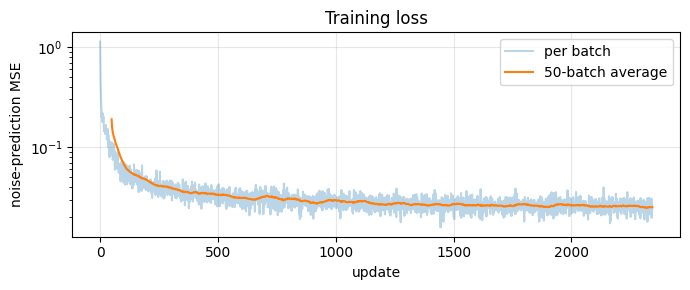

In [9]:
EPOCHS = 5                    # about 2,300 updates; about 3 minutes on a Kaggle T4
BATCH_SIZE = 128
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4)

losses, start = [], time.time()
model.train()
for epoch in range(EPOCHS):
    order = torch.randperm(len(X_train), device=DEVICE)
    for i in range(0, len(X_train), BATCH_SIZE):
        loss = ddpm_loss(model, X_train[order[i:i + BATCH_SIZE]])
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    print(f"epoch {epoch + 1}: mean loss {sum(losses[-469:]) / len(losses[-469:]):.4f}   ({time.time() - start:.0f} s)")
model.eval()

smooth = torch.tensor(losses).unfold(0, 50, 1).mean(1)
plt.figure(figsize=(7, 3)); plt.plot(losses, alpha=0.3, label="per batch"); plt.plot(range(49, len(losses)), smooth, label="50-batch average")
plt.yscale("log"); plt.xlabel("update"); plt.ylabel("noise-prediction MSE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Training loss"); plt.tight_layout(); plt.show()

### What has the network learned?

The loss is an average over all noise levels. Splitting it by timestep, on **test** images the network never saw, shows how hard each level is. We also turn each noise prediction into an estimate of the clean image, by solving the forward equation for $x_0$:

$$\hat x_0 = \frac{x_t - \sqrt{1 - \bar\alpha_t}\,\hat\epsilon}{\sqrt{\bar\alpha_t}}.$$

This is the network's one-shot guess of the clean image from a single noisy view.

    t   noise MSE on test images
   10                     0.1452
  100                     0.0623
  250                     0.0337
  500                     0.0147
  750                     0.0012
  990                     0.0003


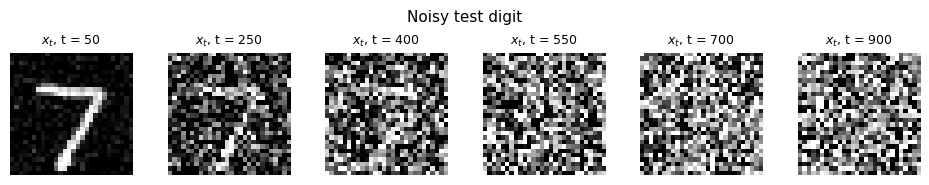

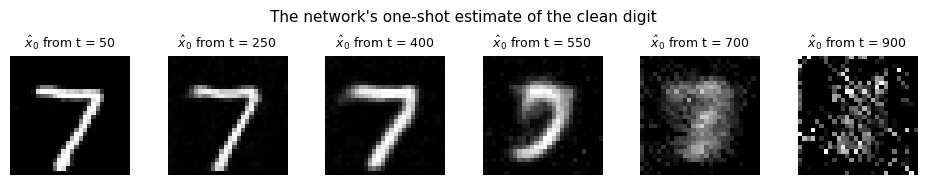

In [10]:
@torch.no_grad()
def estimate_x0(xt, t, predicted_noise):
    # Look up alpha_bar for each image's own timestep, reshaped (B,) -> (B, 1, 1, 1) to broadcast over pixels.
    ab = alpha_bars[t].view(-1, 1, 1, 1)
    # Solve x_t = sqrt(ab) * x0 + sqrt(1 - ab) * noise for x0, using the predicted noise: (B, 1, 28, 28).
    return (xt - (1 - ab).sqrt() * predicted_noise) / ab.sqrt()


# Part 1: noise-prediction error at each noise level, on test images the network never trained on.
# Fix the seed so the random noise, and hence the printed errors, are reproducible.
torch.manual_seed(3)
# The first 1,000 test digits: shape (1000, 1, 28, 28), values in [-1, 1].
x0 = X_test[:1000]
# Table header: the timestep and the mean squared error of the noise prediction.
print(f"{'t':>5}{'noise MSE on test images':>27}")
# From almost clean (t = 10) to almost pure noise (t = 990).
for t_val in (10, 100, 250, 500, 750, 990):
    # Unlike training, every image gets the SAME timestep here, so the error belongs to one noise level: shape (1000,).
    t = torch.full((len(x0),), t_val, device=DEVICE)
    # Fresh N(0, 1) noise for every image and pixel; this is the target to predict: (1000, 1, 28, 28).
    noise = torch.randn_like(x0)
    # Evaluation only: no computation graph is built.
    with torch.no_grad():
        # Noise the images to level t, ask the model for the noise, compare with the true noise: one scalar.
        mse = F.mse_loss(model(add_noise(x0, t, noise), t), noise).item()
    # One row of the table.
    print(f"{t_val:>5}{mse:>27.4f}")

# Part 2: the one-shot clean-image estimate for a single test digit at six noise levels.
# The six timesteps to look at, one per image: shape (6,).
steps = torch.tensor([50, 250, 400, 550, 700, 900], device=DEVICE)
# Six copies of the first test digit: (1, 28, 28) -> (6, 1, 28, 28); expand makes views, not copies in memory.
img = X_test[0].expand(len(steps), -1, -1, -1)
# Noise copy i to level steps[i], each with its own fresh noise: (6, 1, 28, 28).
xt = add_noise(img, steps, torch.randn_like(img))
# Evaluation only: no computation graph is built.
with torch.no_grad():
    # Predict the noise in each noisy copy, then convert that prediction into an estimate of the clean digit: (6, 1, 28, 28).
    x0_hat = estimate_x0(xt, steps, model(xt, steps))
# Top row: what the network sees at each timestep.
show_row(xt, [f"$x_t$, t = {t}" for t in steps.tolist()], suptitle="Noisy test digit")
# Bottom row: the network's single-step guess of the clean digit from each noisy view.
show_row(x0_hat, [f"$\\hat x_0$ from t = {t}" for t in steps.tolist()], suptitle="The network's one-shot estimate of the clean digit")

**Reading the output.** In our run the loss fell from 1.136 to 0.026 over five epochs (175 s), dropping fast in the first few hundred updates and then slowly. Three things to look for.

- **The error is largest at small $t$.** On test images the noise-prediction error was 0.145 at $t = 10$, 0.034 at $t = 250$ and 0.0003 at $t = 990$. When almost no noise has been added, the noise is a tiny perturbation hidden in a nearly clean image, and telling it apart from genuine stroke detail is hard. At large $t$ the input is almost all noise, so "the noise" is almost the input itself. Each noise level is a different task, which is why the network needs $t$.
- **Up to the middle of the schedule the estimates are good, then they lose the digit.** From $t = 50$, 250 and 400 the estimate is a recognisable 7, getting softer. From $t = 550$ it is a smooth, confident-looking digit, but **not the 7**: too little of the original is left to pin it down, and the network guesses another digit that fits the remains. At $t = 700$ it is only a grey blob. Many clean digits are consistent with a heavily noised input, and one guess cannot choose well among them.
- **Near the end of the schedule the estimate turns into speckle.** Low losses at large $t$ do not mean good images. To get $\hat x_0$ we divide by $\sqrt{\bar\alpha_t}$, which is 0.016 at $t = 900$; that magnifies any error in $\hat\epsilon$ about 60 times. Recovering an image from almost pure noise in one shot is hopeless.

This is why we do **not** generate in one shot. Sampling takes many small steps, and each one commits a little more to one particular digit.

## 4. Sampling: from pure noise to a digit

Generation runs the process backwards. Start from pure noise $x_T \sim \mathcal{N}(0, I)$, then for $t = T-1, \dots, 0$:

1. ask the network for the noise in the current image, $\hat\epsilon = \epsilon_\theta(x_t, t)$;
2. take one **reverse step** to a slightly less noisy $x_{t-1}$:

$$x_{t-1} = \frac{1}{\sqrt{1-\beta_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\hat\epsilon\right) + \sqrt{\beta_t}\,z, \qquad z \sim \mathcal{N}(0, I).$$

You do not need to derive this formula (it is Algorithm 2 of Ho et al., 2020). Read it in words: **remove a small, schedule-sized fraction of the predicted noise, rescale, then add back a little fresh noise.** The fresh noise $z$ keeps the process random, so different runs produce different images; it is left out at the final step, so that the output is a clean image.

That is the sampling loop. Unlike training, it calls the network once per step: **1,000 network calls** for one batch of images.

generated 32 digits with 1000 network calls in 7.1 s


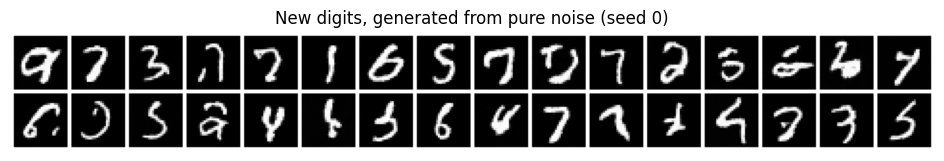

In [11]:
@torch.no_grad()
def reverse_step(eps_model, x, t):
    """One DDPM reverse step x_t -> x_(t-1) for a whole batch at the same timestep t (a Python int)."""
    # x: (B, 1, 28, 28) noisy images at timestep t
    # t: a single integer timestep for the whole batch, e.g. 999, 500, 0
    # Sampling uses ONE timestep for the whole batch (unlike training); the network still wants one per image: shape (B,).
    # if t= 600 then t_batch = [600, 600, 600, ..., 600] -> shape (B,)
    t_batch = torch.full((x.shape[0],), t, device=x.device, dtype=torch.long)
    # The network's prediction of the noise in every image: (B, 1, 28, 28).
    eps_hat = eps_model(x, t_batch)
    # Remove a schedule-sized fraction of the predicted noise, then rescale by 1 / sqrt(1 - beta_t) (alphas[t] = 1 - betas[t]).
    mean = (x - betas[t] / (1 - alpha_bars[t]).sqrt() * eps_hat) / alphas[t].sqrt()
    # Last step (t = 0): no fresh noise, so the output is a clean image.
    if t == 0:
        return mean, eps_hat
    # Every other step: add fresh noise sqrt(beta_t) * z with z ~ N(0, I); this keeps sampling random.
    return mean + betas[t].sqrt() * torch.randn_like(x), eps_hat


@torch.no_grad()
def sample(eps_model, shape, seed=0, keep=()):
    """Generate images of `shape` from pure noise. Returns the images and snapshots {t: (x_t, x0_estimate)} at the steps in `keep`."""
    # The seed fixes the starting noise and the fresh noise of every step, so the same seed gives the same images.
    torch.manual_seed(seed)
    # x_T: pure Gaussian noise, e.g. (32, 1, 28, 28). No image is hidden in it.
    x = torch.randn(shape, device=DEVICE)
    snapshots = {}
    # Walk backwards t = 999, 998, ..., 0: 1,000 network calls, one after another, each needing the previous output.
    for t in reversed(range(T)):
        # Keep x_t before the step, in case we snapshot this timestep.
        x_before = x
        # One reverse step x_t -> x_(t-1); also returns the predicted noise, reused for the snapshot below.
        x, eps_hat = reverse_step(eps_model, x, t)
        # Record only the timesteps listed in `keep`.
        if t in keep:
            # estimate_x0 looks up alpha_bar per image, so it needs a timestep tensor of shape (B,).
            t_batch = torch.full((shape[0],), t, device=DEVICE)
            # Store the current image and the one-shot clean estimate (clamped to the pixel range [-1, 1]), on the CPU.
            snapshots[t] = (x_before.cpu(), estimate_x0(x_before, t_batch, eps_hat).clamp(-1, 1).cpu())
    return x, snapshots


start = time.time()
# Generate 32 digits from seed 0, keeping snapshots at 7 timesteps for the next cell.
generated, snaps = sample(model, (32, 1, 28, 28), seed=0, keep=(999, 800, 600, 400, 200, 50, 0))
# GPU work runs asynchronously: wait until it has finished, so the measured time is correct.
if DEVICE == "cuda":
    torch.cuda.synchronize()
print(f"generated {len(generated)} digits with {T} network calls in {time.time() - start:.1f} s")
show_grid(generated, nrow=16, title="New digits, generated from pure noise (seed 0)", size=12)

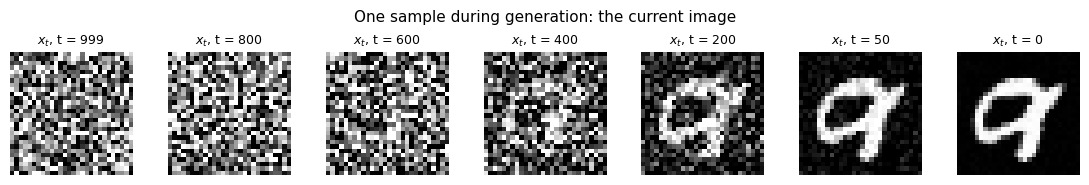

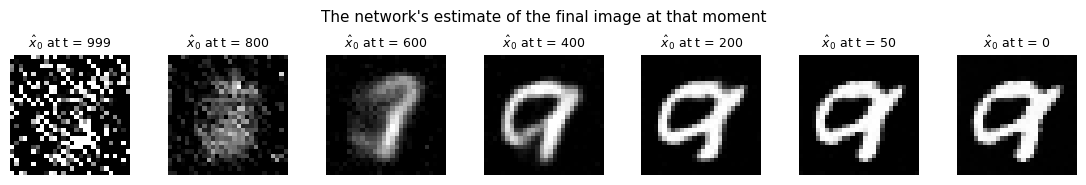

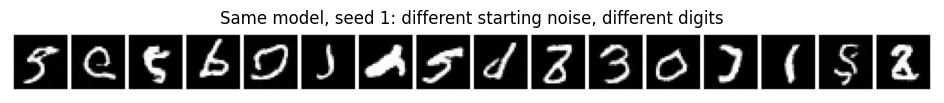

In [12]:
# Snapshot timesteps from noisiest to cleanest: 999, 800, 600, 400, 200, 50, 0.
order = sorted(snaps, reverse=True)
# snaps[t][0] is x_t for the whole batch; the final [0] picks the first of the 32 samples.
show_row([snaps[t][0][0] for t in order], [f"$x_t$, t = {t}" for t in order], suptitle="One sample during generation: the current image")
# snaps[t][1] is the clean-image estimate at that step, again for the first sample.
show_row([snaps[t][1][0] for t in order], [f"$\\hat x_0$ at t = {t}" for t in order], suptitle="The network's estimate of the final image at that moment")

# Same trained model, different seed: different starting noise, so different digits. No snapshots are kept.
other, _ = sample(model, (16, 1, 28, 28), seed=1)
show_grid(other, nrow=16, title="Same model, seed 1: different starting noise, different digits", size=12)

**Reading the output.**

- 32 digits took 1,000 network calls and 7.1 s on the T4. After three minutes of training, most samples are recognisable digits (9, 7, 3, 1, 6, 5 and so on), but several have broken or extra strokes and some are not any digit at all. More training, a larger network, and the improvements of Lecture 2 all help.
- The **current image** $x_t$ is still mostly noise at $t = 400$, shows a faint digit at $t = 200$, and is nearly clean by $t = 50$; the noise is removed gradually. The **estimate** $\hat x_0$ shows when the decisions are made. At $t = 999$ it is speckle (the amplified error of Section 3), at $t = 800$ a faint cloud, at $t = 600$ a blurry vertical stroke, and by $t = 400$ the 9 is already decided. From then on only the thickness and fine shape of the strokes change. Coarse structure first, detail last: the forward process in reverse.
- A different **seed** gives different starting noise and therefore different digits. The seed does not pick the digit class: this model has no notion of class at all. Telling it *which* digit to draw is **conditioning**, in Lecture 2.

### Is it copying its training data?

A generated image could, in principle, be a near copy of a training image: diffusion models can memorise, and large ones have been shown to reproduce some training images almost exactly (Carlini et al., 2023). A simple first check is to find, for each sample, the **nearest training image** in pixel space, and compare that distance with a baseline: how far real **test** digits are from their nearest training image. Samples much closer than real test digits would suggest copying.

distance to nearest training image: generated samples median 10.33 | real test digits median 8.76


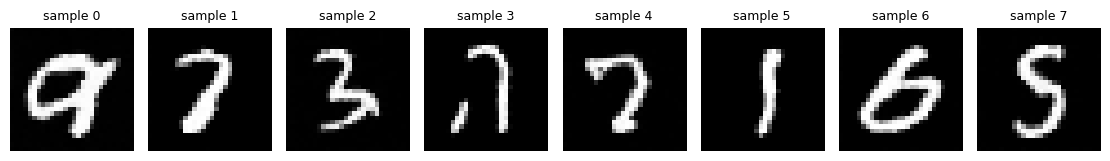

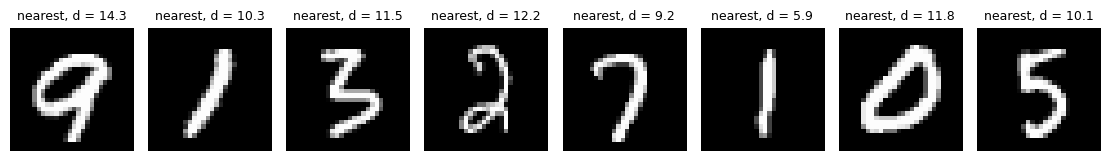

In [13]:
@torch.no_grad()
def nearest_train(images):
    """For each image, the closest MNIST training image (Euclidean distance over pixels) and that distance."""
    # Each training image becomes one row of 784 pixel values: (60000, 1, 28, 28) -> (60000, 784).
    flat_train = X_train.flatten(1)
    # Flatten the query images the same way, (n, 784), and compute every query-to-training distance: (n, 60000).
    d = torch.cdist(images.flatten(1).to(DEVICE), flat_train)
    # For each query, the smallest distance and the index of the training image it belongs to: both of shape (n,).
    dist, idx = d.min(dim=1)
    return dist.cpu(), idx.cpu()


# The first 8 generated digits; clamp to the pixel range [-1, 1] of the training data, since samples can overshoot it slightly.
gen_dist, gen_idx = nearest_train(generated[:8].clamp(-1, 1))
# Baseline: how far 500 real test digits, which are certainly not copies, are from their nearest training image.
test_dist, _ = nearest_train(X_test[:500])
# Compare medians: samples much closer than real test digits would suggest copying.
print(f"distance to nearest training image: generated samples median {gen_dist.median():.2f} | real test digits median {test_dist.median():.2f}")
# Top row: the generated samples.
show_row(generated[:8], [f"sample {i}" for i in range(8)], size=1.4)
# Bottom row: the training image closest to each sample, titled with its distance.
show_row(X_train[gen_idx.to(DEVICE)], [f"nearest, d = {d:.1f}" for d in gen_dist.tolist()], size=1.4)

**Reading the output.** In our run, the median distance to the nearest training image was 10.33 for the generated samples and 8.76 for real test digits. The samples are no closer to the training set than unseen real digits are, so there is no sign of copying. Look at the pairs, too. Several nearest neighbours are a **different digit**: the generated 7 is closest to a 1, and the generated 6 to a 0. The smallest distance (5.9) belongs to a thin 1, simply because thin digits have few lit pixels. Pixel distance measures overlap of ink, not what a digit is. This is a weak check: pixel distance misses copies that are shifted or slightly altered, and a model trained on 60,000 simple digits for a few minutes has little capacity to memorise. For large models trained on scraped images, memorisation is a real privacy and copyright risk (Carlini et al., 2023).

## 5. The same loop on a published model

Our digit model has 1.6 million parameters. Ho et al. (2020) trained a 35.7-million-parameter U-Net on CIFAR-10, a dataset of 32 × 32 colour photographs of ten kinds of object (Krizhevsky, 2009), with the **same schedule** we have been using (linear $\beta_t$ from 0.0001 to 0.02, $T = 1000$). Its weights are published on the Hugging Face Hub, and the `diffusers` library can load the U-Net. We use only the network: the sampling loop is our own `sample` function from Section 4, unchanged.

> **Download:** the next cell installs `diffusers` if it is missing and downloads `google/ddpm-cifar10-32` (143 MB, Apache-2.0). No Hugging Face account is needed. Warnings about unauthenticated requests or deprecated arguments can be ignored.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/699 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  143MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

diffusers 0.40.0 | parameters: 35.7 M
16 images, 1000 network calls: 56.3 s


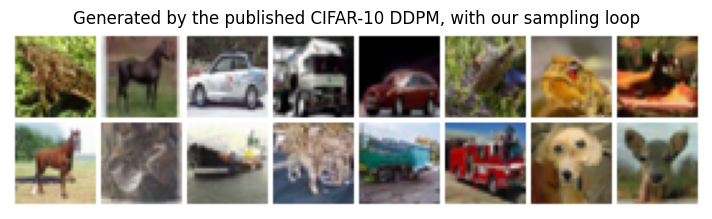

In [14]:
try:
    import diffusers
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    import diffusers
from diffusers import UNet2DModel

cifar_unet = UNet2DModel.from_pretrained("google/ddpm-cifar10-32").to(DEVICE).eval()
print("diffusers", diffusers.__version__, f"| parameters: {sum(p.numel() for p in cifar_unet.parameters()) / 1e6:.1f} M")


def cifar_eps(x, t):
    return cifar_unet(x, t).sample            # the diffusers U-Net returns an object; .sample is the predicted noise


start = time.time()
cifar_images, cifar_snaps = sample(cifar_eps, (16, 3, 32, 32), seed=0, keep=(999, 700, 500, 300, 150, 50, 0))
if DEVICE == "cuda":
    torch.cuda.synchronize()
print(f"16 images, {T} network calls: {time.time() - start:.1f} s")
show_grid(cifar_images, nrow=8, title="Generated by the published CIFAR-10 DDPM, with our sampling loop", size=9)

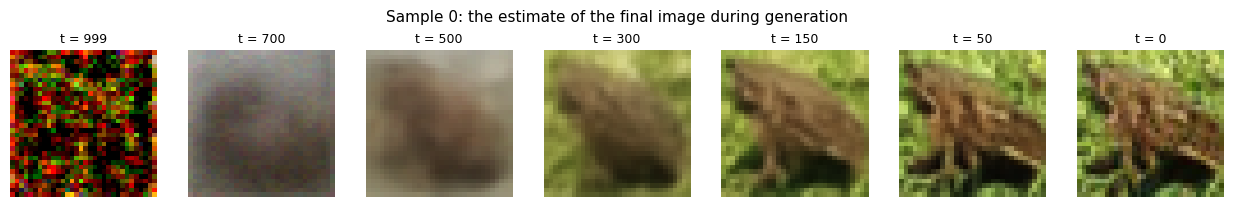

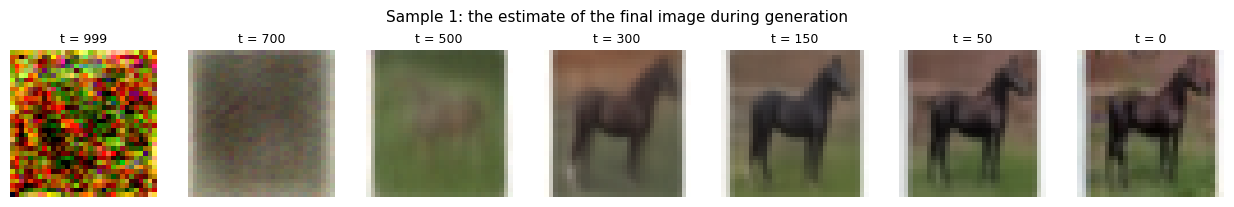

In [15]:
order = sorted(cifar_snaps, reverse=True)
for i in (0, 1):
    show_row([cifar_snaps[t][1][i] for t in order], [f"t = {t}" for t in order], size=1.8,
             suptitle=f"Sample {i}: the estimate of the final image during generation")

**Reading the output.** The samples are only 32 × 32, yet most can be named. In our run they included frogs, horses, cars, trucks, a fire engine, a ship, a dog and a deer, each with a plausible background; a few were unclear. None of the ten classes was requested: the model is unconditional, as ours is. The estimates show the same coarse-to-fine order as the digits, now with colour. At $t = 999$ they are coloured speckle and at $t = 700$ a grey haze. At $t = 500$ the colour layout appears: a brown shape on a light background for the frog, a green field for the horse. The object's outline is settled by $t = 300$, and texture (grass, the frog's skin) arrives last.

Two practical differences from the original implementation are worth knowing. The `diffusers` scheduler clips the estimate $\hat x_0$ to $[-1, 1]$ at each step, which our loop does not; and published results use many more samples and careful evaluation. Our loop is Algorithm 2 of the paper as written.

**The cost.** Every image needed 1,000 sequential calls to a 35.7-million-parameter network: 56 s for 16 images on the T4, against 7 s for 32 digits with our small model. The calls cannot be run in parallel, because each step needs the output of the previous one. A GAN generator would need one call. Making sampling faster without retraining is the first topic of Lecture 2.

## 6. Training and sampling side by side

| | Training | Sampling (generation) |
| --- | --- | --- |
| Starts from | A real image $x_0$ | Pure noise $x_T$ |
| Noise | Added once, at a random level $t$, by the fixed forward process | Removed a little at each of $T$ steps |
| Network calls per image | 1 per update | $T$ (here 1,000), one after another |
| Target known? | Yes: the noise we added | No target; nothing to compare with |
| Weights | Updated by the loss | Frozen |
| Output | A loss value | A new image |

| Component | Fixed or learned? |
| --- | --- |
| Noise schedule $\beta_t$, $\bar\alpha_t$ | Fixed by the designer |
| Forward process (adding noise) | Fixed |
| Noise-prediction network $\epsilon_\theta$ | **Learned** |
| Reverse step formula | Fixed; it uses the learned network's prediction |

### What a generated image is, and is not

- **A sample, not a recovery.** Starting from pure noise, the model produces an image that is plausible under its training data. No image was hidden in the noise. The same holds when diffusion is used to "enhance" images: added detail is generated, not recovered, and must not be treated as evidence.
- **A reflection of the training data.** The model can only produce what its data makes likely, including its gaps and biases. A face model trained mostly on one group of people will generate mostly that group.
- **Possibly a copy.** Large diffusion models can reproduce training images (Carlini et al., 2023), which matters when the training data includes private or copyrighted images.

## 7. Summary

| Idea | In one line |
| --- | --- |
| Forward process (Lecture 1a) | Fixed: $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$ mixes image and noise at any level in one step |
| Noise schedule (Lecture 1a) | Fixed $\beta_t$; $\bar\alpha_t$ falls from about 1 to about 0, so $x_T$ is pure noise |
| What is learned | A U-Net $\epsilon_\theta(x_t, t)$ that predicts the noise in $x_t$, told the noise level through a timestep embedding |
| Training | Random $t$, fresh noise, one forward step, mean squared error against the noise added |
| Sampling | From pure noise, $T$ reverse steps: remove some predicted noise, add a little fresh noise |
| Behaviour | Coarse structure first, fine detail last; the seed changes the sample |
| Cost | $T$ sequential network calls per sample: the main weakness, addressed in Lecture 2 |

**Next lecture:** making diffusion better and faster: other noise schedules, conditioning on a class label with classifier-free guidance, and DDIM, a sampler that uses the same trained network with far fewer steps.

## 8. Check your understanding

1. Why can we not generate an image by subtracting noise from a random tensor? What does the network provide that subtraction cannot?
2. During training, how many timesteps does each image see in one update? How many network calls does generating one image take? Why the difference?
3. The network is given $t$ as an input. What would go wrong if it were not? Use the per-timestep error table from Section 3 in your answer.
4. In Section 3, the one-shot estimate $\hat x_0$ of the test 7 became a different digit at $t = 550$ and speckle at $t = 900$. Explain each, and why this argues for many small reverse steps.
5. What does the fresh noise $z$ in the reverse step do? What would you expect if it were removed at every step?
6. A diffusion model is used to sharpen a blurry security-camera image of a car's number plate. Why must the result not be used as evidence of the plate number?
7. Which parts of a DDPM are fixed, and which are learned? Where in Lectures 1a and 1b is each one?

## References

- Carlini, N., Hayes, J., Nasr, M., et al. (2023). Extracting training data from diffusion models. *USENIX Security Symposium*. [arXiv:2301.13188](https://arxiv.org/abs/2301.13188)
- Elfwing, S., Uchibe, E., & Doya, K. (2018). Sigmoid-weighted linear units for neural network function approximation in reinforcement learning. *Neural Networks*, 107, 3–11. [arXiv:1702.03118](https://arxiv.org/abs/1702.03118)
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Identity mappings in deep residual networks. *ECCV 2016*. [arXiv:1603.05027](https://arxiv.org/abs/1603.05027)
- Ho, J., Jain, A., & Abbeel, P. (2020). Denoising diffusion probabilistic models. *NeurIPS 2020*. [arXiv:2006.11239](https://arxiv.org/abs/2006.11239) · weights: [`google/ddpm-cifar10-32`](https://huggingface.co/google/ddpm-cifar10-32)
- Krizhevsky, A. (2009). *Learning multiple layers of features from tiny images* (CIFAR-10). Technical report, University of Toronto.
- LeCun, Y., Cortes, C., & Burges, C. J. C. The MNIST database of handwritten digits.
- Ramachandran, P., Zoph, B., & Le, Q. V. (2017). Searching for activation functions. [arXiv:1710.05941](https://arxiv.org/abs/1710.05941)
- Ronneberger, O., Fischer, P., & Brox, T. (2015). U-Net: Convolutional networks for biomedical image segmentation. *MICCAI 2015*. [arXiv:1505.04597](https://arxiv.org/abs/1505.04597)
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *NeurIPS 2017*. [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
- Wu, Y., & He, K. (2018). Group normalization. *ECCV 2018*. [arXiv:1803.08494](https://arxiv.org/abs/1803.08494)
- Hugging Face. *Diffusers* documentation. <https://huggingface.co/docs/diffusers>